# 02 — Scaled v3 experiment analysis

Europarl scaled v3: 12,000 train / 1,500 validation / 1,500 test sentence pairs. This notebook reads saved predictions and metrics without generating new translations. GPT-6 Astra is the C/D post-editor. The sampling comparison below uses GPT-6 reranking. Set `EXPERIMENT_SPLIT` to `validation` or `test` before execution. The older v2 experiment remains available through its saved results and Git history; no v2 outputs are loaded here.


In [1]:
from pathlib import Path
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATASET = "europarl_scaled_v3"
START = Path.cwd().resolve()
PROJECT_ROOT = next(
    (directory for directory in (START, *START.parents)
     if (directory / "data" / "processed" / DATASET).is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Dataset {DATASET} not found above {START}")
SPLIT = os.environ.get("EXPERIMENT_SPLIT", "validation")  # Set to test for the already-frozen final evaluation.
assert SPLIT in {"validation", "test"}
DATA_DIR = PROJECT_ROOT / "data" / "processed" / DATASET
assert DATA_DIR.is_dir(), f"Missing dataset: {DATA_DIR}"
POSTEDIT_MODEL = os.environ.get("POSTEDIT_MODEL", "gpt6").lower()
assert POSTEDIT_MODEL == "gpt6"
LLM_SUFFIX = "_llm_gpt6"
COMET_SUFFIX = "_gpt6"
ARMS = {
    "A": "sentence_lora_balanced_scaled_v3",
    "B": "context_lora_balanced_scaled_v3",
    "C": f"sentence_lora_balanced_scaled_v3{LLM_SUFFIX}",
    "D": f"context_lora_balanced_scaled_v3{LLM_SUFFIX}",
}
KEYS = ["pair", "doc_id", "src_sent_id", "tgt_sent_id"]
print(f"Project: {PROJECT_ROOT} | Dataset: {DATASET} | Split: {SPLIT} | LLM: {POSTEDIT_MODEL}")


Project: D:\CIS600\context-mt | Dataset: europarl_scaled_v3 | Split: test | LLM: gpt6


## Dataset provenance

Verify the exact CSV and builder manifest for this split. Predictions in A/B/C/D must align on the same sentence keys and source/reference text.


In [2]:
manifest = json.loads((DATA_DIR / "summary.json").read_text(encoding="utf-8"))
data_path = DATA_DIR / f"{SPLIT}.csv"
import hashlib
actual_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert manifest["csv_sha256"][SPLIT] == actual_hash, "Dataset differs from summary.json"
truth = pd.read_csv(data_path)
assert truth["split"].eq(SPLIT).all()
assert not truth.duplicated(KEYS).any(), "Duplicate example keys in dataset"
display(truth.groupby("pair").agg(examples=("src", "size"), documents=("doc_id", "nunique")))
print(f"SHA256 {SPLIT}: {actual_hash}")


,examples,documents
pair,,
en-de,1000,100
en-fr,500,100


SHA256 test: da60b889f669bb1f1af8808e270d5d75a984f520429057432cc035c075ab0381


## Four-arm comparison

A/B prediction tables come from mBART evaluation; C/D come from the selected LLM post-editor. GPT-6 is the C/D post-editor. Scores use the saved SacreBLEU and chrF metrics with one consistent reference per example. The code verifies both dataset hash provenance and row alignment before displaying a model.


In [3]:
reports, predictions, missing = {}, {}, []
for arm, run in ARMS.items():
    pred_path = PROJECT_ROOT / "outputs" / "predictions" / f"{run}_{SPLIT}.csv"
    metric_path = PROJECT_ROOT / "outputs" / "metrics" / f"{run}_{SPLIT}_metrics.json"
    if not pred_path.is_file() or not metric_path.is_file():
        missing.append(f"{arm}: {pred_path.name} / {metric_path.name}")
        continue
    report = json.loads(metric_path.read_text(encoding="utf-8"))
    if arm in "AB":
        assert report.get("dataset_sha256") == actual_hash, f"{arm}: metric dataset hash mismatch"
        assert report.get("split") == SPLIT, f"{arm}: wrong split"
    else:
        assert report.get("split") == SPLIT and not report.get("smoke_test"), f"{arm}: wrong split or smoke result"
        if POSTEDIT_MODEL == "gpt6":
            assert report.get("config", {}).get("provider") == "openai", f"{arm}: expected OpenAI post-edit"
    table = pd.read_csv(pred_path)
    assert len(table) == len(truth), f"{arm}: example count mismatch"
    assert not table.duplicated(KEYS).any(), f"{arm}: duplicate keys"
    aligned = truth[KEYS + ["src", "tgt", "previous_src"]].merge(
        table[KEYS + ["src", "tgt", "previous_src", "prediction"]],
        on=KEYS, how="left", validate="one_to_one", suffixes=("_gold", "_out"),
    )
    assert aligned["prediction"].notna().all(), f"{arm}: missing predictions"
    for field in ("src", "tgt", "previous_src"):
        assert aligned[f"{field}_gold"].equals(aligned[f"{field}_out"]), f"{arm}: {field} mismatch"
    reports[arm], predictions[arm] = report, aligned["prediction"].reset_index(drop=True)
print("Available arms:", ", ".join(reports) or "none yet")
if missing:
    print("Pending outputs:")
    for entry in missing:
        print(" -", entry)


Available arms: A, B, C, D


,arm,pair,N,BLEU,chrF
0,A,en-de,1000,29.194,59.010
1,A,en-fr,500,38.017,64.506
2,A,macro,1500,33.606,61.758
3,B,en-de,1000,28.698,58.768
4,B,en-fr,500,38.325,64.606
5,B,macro,1500,33.512,61.687
6,C,en-de,1000,33.041,62.230
7,C,en-fr,500,41.129,66.940
8,C,macro,1500,37.085,64.585
9,D,en-de,1000,32.706,62.066


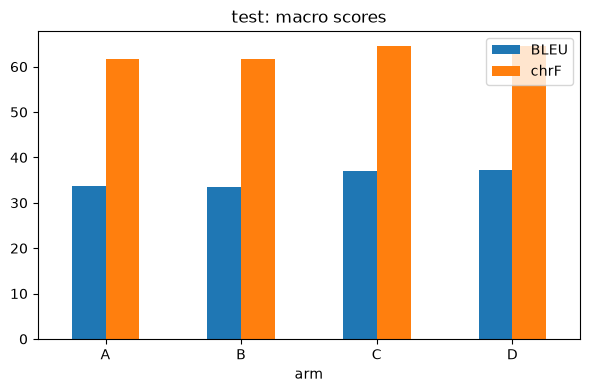

In [4]:
rows = []
for arm, report in reports.items():
    for pair in ("en-de", "en-fr"):
        pair_report = report["pairs"][pair]
        score = pair_report if arm in "AB" else pair_report["postedited"]
        rows.append({"arm": arm, "pair": pair, "N": pair_report["num_examples"],
                     "BLEU": score["sacrebleu"], "chrF": score["chrf"]})
    pair_rows = rows[-2:]
    rows.append({"arm": arm, "pair": "macro", "N": sum(r["N"] for r in pair_rows),
                 "BLEU": sum(r["BLEU"] for r in pair_rows) / 2,
                 "chrF": sum(r["chrF"] for r in pair_rows) / 2})
score_table = pd.DataFrame(rows, columns=["arm", "pair", "N", "BLEU", "chrF"])
if score_table.empty:
    print("Predictions and metrics for the chosen split are pending.")
else:
    display(score_table.round(3))
    macro = score_table[score_table["pair"] == "macro"].set_index("arm")
    display(macro[["BLEU", "chrF"]].plot.bar(rot=0, figsize=(7, 4), title=f"{SPLIT}: macro scores").figure)
    plt.close("all")


## Paired changes and qualitative examples

Compare translations for the **same** rows. Sentence-level chrF identifies candidates for manual inspection; it does not prove that a model resolved a pronoun or improved discourse. Review the source, preceding source and both translations before writing such claims in the report.


In [5]:
from sacrebleu.metrics import CHRF
chrf_metric = CHRF()
reference = truth["tgt"].tolist()
comparisons = {"context B − A": ("A", "B"), "LLM C − A": ("A", "C"),
               "LLM D − B": ("B", "D"), "context D − C": ("C", "D")}
summary = []
example_tables = {}
for name, (before, after) in comparisons.items():
    if before not in predictions or after not in predictions:
        continue
    old, new = predictions[before].tolist(), predictions[after].tolist()
    delta = [chrf_metric.sentence_score(b, [ref]).score -
             chrf_metric.sentence_score(a, [ref]).score
             for a, b, ref in zip(old, new, reference)]
    review = truth[KEYS + ["previous_src", "src", "tgt"]].copy()
    review[f"prediction_{before}"] = old
    review[f"prediction_{after}"] = new
    review["delta_sentence_chrF"] = delta
    example_tables[name] = review
    summary.append({"comparison": name, "changed": sum(a != b for a, b in zip(old, new)),
                    "helped": sum(d > 1e-9 for d in delta), "hurt": sum(d < -1e-9 for d in delta),
                    "tied": sum(abs(d) <= 1e-9 for d in delta),
                    "mean_sentence_chrF_delta": sum(delta) / len(delta)})
if summary:
    display(pd.DataFrame(summary).round(3))
    for name, table in example_tables.items():
        print(f"{name} — five largest positive changes")
        display(table.nlargest(5, "delta_sentence_chrF"))
        print(f"{name} — five largest negative changes")
        display(table.nsmallest(5, "delta_sentence_chrF"))
else:
    print("At least two complete arms are needed for paired examples.")


,comparison,changed,helped,hurt,tied,mean_sentence_chrF_delta
0,context B − A,774,384,380,736,0.025
1,LLM C − A,1025,757,259,484,3.022
2,LLM D − B,1058,761,285,454,3.106
3,context D − C,838,407,422,671,0.110


context B − A — five largest positive changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_A,prediction_B,delta_sentence_chrF
78,en-de,en/ep-09-05-07-010.xml,142,156,Greenland has around twice the population of G...,Denmark gave 8% of its seats to 50 000 people.,Dänemark gab 8% seiner Sitze an 50 000 Menschen.,Dänemark hat 8% seiner Sitze für 50 000 Person...,Dänemark hat 8 % seiner Sitze an 50 000 Mensch...,29.819578
1290,en-de,en/ep-96-09-19.xml,2085,2173,The waterways represented the main cultural an...,The Mediterranean is Europe's link with Africa...,Das Mittelmeer ist Europas Verbindung zu Afrik...,Der Mittelmeerraum ist die Verbindung Europas ...,Das Mittelmeer ist Europas Verbindung zu Afrik...,28.254005
118,en-de,en/ep-08-01-15-010-02.xml,18,21,"Mr Hannan, to my knowledge, all votes which ha...",Therefore the Rules have been complied with me...,Folglich wurde die Geschäftsordnung akribisch ...,Deshalb wurden die Regeln sorgfältig eingehalten.,Daher wurden die Geschäftsordnungen sorgfältig...,25.163166
62,en-de,en/ep-08-07-07-014.xml,3,3,"The final draft agenda for this part-session, ...",The following amendments have been requested t...,Zu diesem Entwurf wurden folgende Änderungen b...,Folgende Änderungsanträge wurden an diesen Ent...,Zu diesem Entwurf wurden folgende Änderungsant...,22.851978
64,en-de,en/ep-06-05-18.xml,859,942,The tens of thousands who have been sent into ...,I now expect the Tibetan refugee centre and th...,"Ich rechne jetzt damit, dass auch das Flüchtli...",Ich erwarte nun die Wiedereröffnung des Tibete...,"Ich erwarte nun, dass das tibetische Flüchtlin...",19.083181


context B − A — five largest negative changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_A,prediction_B,delta_sentence_chrF
1029,en-de,en/ep-04-07-20.xml,161,164,Even though all the opinion polls show that Eu...,This is one of Parliament ’ s foremost tasks.,Das ist eine der wichtigsten Aufgaben für das ...,Das ist eine der wichtigsten Aufgaben des Parl...,Das ist eine der Hauptaufgaben des Parlaments.,-24.891832
910,en-de,en/ep-00-03-02.xml,306,319,"Hence, the relevance of your second question o...",The procedure for verifying the origin of prod...,Das Verfahren zur Überprüfung des Ursprungs de...,Das Verfahren zur Überprüfung des Ursprungs vo...,Mit dem Verfahren zur Herkunftskontrolle könne...,-23.704779
718,en-de,en/ep-97-10-22.xml,3081,3049,"Mr President, this evening we are discussing a...","Previously, additives were called foreign ingr...",Früher hießen Zusatzstoffe Fremdstoffe.,Zuvor hießen Zusatzstoffe ausländische Inhalts...,Zuvor wurden Zusätze als Fremdstoffe bezeichnet.,-21.783271
999,en-de,en/ep-02-05-13.xml,1362,1459,"However, for this to become a reality, we need...",What I am deeply concerned about is the lack o...,Sehr große Sorgen bereitet mir der Mangel an G...,"Was mich sehr beunruhigt, ist das Fehlen von G...","Was mich sehr beunruhigt, ist das Fehlen von G...",-19.207485
37,en-de,en/ep-11-02-03-009.xml,1695,1722,"It is necessary for the EU criteria to be met,...",There is an urgent need to make an effort to r...,"Es ist dringend erforderlich, Anstrengungen zu...","Es ist dringend erforderlich, Anstrengungen zu...","Es besteht dringende Notwendigkeit, die Abfall...",-18.878311


LLM C − A — five largest positive changes


... (7 outputs left out)

context D − C — five largest positive changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_C,prediction_D,delta_sentence_chrF
691,en-de,en/ep-10-03-10-008.xml,144,152,I wonder whether they would have preferred it ...,Would that have been a proportionate response?,Wäre das eine verhältnismäßige Reaktion gewesen?,Wäre das eine angemessene Antwort gewesen?,Wäre das eine verhältnismäßige Reaktion gewesen?,57.860044
118,en-de,en/ep-08-01-15-010-02.xml,18,21,"Mr Hannan, to my knowledge, all votes which ha...",Therefore the Rules have been complied with me...,Folglich wurde die Geschäftsordnung akribisch ...,Deshalb wurden die Regeln sorgfältig eingehalten.,Daher wurde die Geschäftsordnung sorgfältig ei...,30.975051
1148,en-fr,en/ep-07-05-09-019.xml,26,26,The resolution and prevention of conflicts in ...,The first level concerns the standard way of m...,Le premier niveau concerne la voie classique d...,Le premier niveau concerne le mode normal de m...,Le premier niveau concerne la voie classique d...,30.846165
1118,en-de,en/ep-09-09-17-005.xml,90,102,"Mr President, last week saw the re-release of ...",This week we are debating the milk quota syste...,In diesee Woche diskutieren wir über ein Milch...,Wir diskutieren in dieser Woche über das Milch...,Diese Woche diskutieren wir über das Milchquot...,29.080905
807,en-de,en/ep-98-07-13.xml,646,659,"Moreover, it is important to propose a policy ...",That is what my report and my resolution purpo...,Das ist Inhalt meines Berichts und meiner Ents...,"Das ist es, was mein Bericht und meine Entschl...",Das ist das Ziel meines Berichts und meiner En...,27.444993


context D − C — five largest negative changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_C,prediction_D,delta_sentence_chrF
741,en-de,en/ep-97-10-22.xml,2083,2037,One of these has always been for us that goods...,That has always been the basic understanding o...,Das war immer das Credo unserer Lebensmittelge...,Das war schon immer das Grundverständnis unser...,Das ist seit jeher das Grundverständnis unsere...,-30.914877
1029,en-de,en/ep-04-07-20.xml,161,164,Even though all the opinion polls show that Eu...,This is one of Parliament ’ s foremost tasks.,Das ist eine der wichtigsten Aufgaben für das ...,Das ist eine der wichtigsten Aufgaben des Parl...,Das ist eine der Hauptaufgaben des Parlaments.,-24.891832
257,en-de,en/ep-08-05-19-020.xml,137,141,"Mr President, I would like to thank the rappor...","Having said that, I would like to make three p...",Dennoch möchte ich drei Punkte ansprechen.,Dennoch möchte ich drei Punkte ansprechen.,"Nachdem dies gesagt ist, möchte ich drei Punkt...",-24.639884
781,en-de,en/ep-09-11-24-014.xml,130,135,"In my opinion, liberalising the trade of agric...",Realisation of such an exceptionally ambitious...,Die Realisierung eines solch außerordentlich a...,Die Realisierung eines so außerordentlich ehrg...,Die Umsetzung eines außergewöhnlich ehrgeizige...,-23.989470
396,en-de,en/ep-09-02-18-023.xml,56,59,One could argue that emerging countries are in...,We will examine this as part of the review.,Wir werden diesen Punkt im Rahmen der Prüfung ...,Wir werden dies im Rahmen der Überprüfung unte...,Wir werden dies im Rahmen der Überprüfung prüfen.,-21.789768


## COMET

Read saved reference-based COMET results for A/B/C/D on the selected split and selected post-editor. Small descriptive mean differences do not by themselves establish statistical significance or a causal context effect.


In [6]:
comet_path = PROJECT_ROOT / "outputs" / "metrics" / f"comet_{SPLIT}_scaled_v3{COMET_SUFFIX}_metrics.json"
if comet_path.is_file():
    comet_report = json.loads(comet_path.read_text(encoding="utf-8"))
    assert comet_report.get("dataset") == "scaled_v3"
    assert comet_report.get("split") == SPLIT
    if POSTEDIT_MODEL == "gpt6":
        assert comet_report.get("postedit_model") == "gpt6"
    assert comet_report["inputs"]["dataset"]["sha256"] == actual_hash
    comet_rows = []
    for arm, details in comet_report["arms"].items():
        for pair, metrics in details["pairs"].items():
            comet_rows.append({"arm": arm, "pair": pair, "COMET": metrics["comet_mean"]})
        comet_rows.append({"arm": arm, "pair": "macro",
                           "COMET": details["macro_average_comet"]})
    display(pd.DataFrame(comet_rows).round(4))
    display(pd.DataFrame([{"comparison": name, "COMET delta": value["macro_comet_delta"]}
                          for name, value in comet_report["comparisons"].items()]).round(4))
else:
    print(f"COMET pending: {comet_path.name}")


,arm,pair,COMET
0,A,en-de,0.8674
1,A,en-fr,0.8725
2,A,macro,0.8700
3,B,en-de,0.8663
4,B,en-fr,0.8727
5,B,macro,0.8695
6,C,en-de,0.8858
7,C,en-fr,0.8901
8,C,macro,0.8879
9,D,en-de,0.8863


,comparison,COMET delta
0,context_without_llm,-0.0005
1,llm_sentence,0.0180
2,llm_context,0.0192
3,context_with_llm,0.0008


## Paired document bootstrap

Intervals resample shared document IDs across both language pairs. C−A and D−B measure GPT-6 post-editing against its matching mBART draft. D−C isolates the small context difference after post-editing. Interpret these conditional intervals alongside BLEU, chrF and human review; the notebook reads saved JSON and does not call an LLM.


In [7]:
bootstrap_path = PROJECT_ROOT / "outputs" / "metrics" / f"document_bootstrap_{SPLIT}_scaled_v3{COMET_SUFFIX}.json"
if bootstrap_path.is_file():
    bootstrap = json.loads(bootstrap_path.read_text(encoding="utf-8"))
    assert bootstrap.get("split") == SPLIT
    assert bootstrap.get("postedit_model") == POSTEDIT_MODEL
    assert bootstrap.get("examples") == len(truth)
    intervals = []
    for metric, contrasts in bootstrap["results"].items():
        for name, result in contrasts.items():
            lo, hi = result["ci95_percentile"]
            intervals.append({"metric": metric, "contrast": name,
                              "delta": result["observed_delta"], "CI low": lo, "CI high": hi})
    display(pd.DataFrame(intervals).round(4))
else:
    print("Document bootstrap pending:", bootstrap_path)


,metric,contrast,delta,CI low,CI high
0,bleu,context_B_minus_A,-0.0939,-0.4263,0.2069
1,bleu,llm_on_sentence_C_minus_A,3.4794,2.8721,4.0667
2,bleu,llm_on_context_D_minus_B,3.6592,3.0635,4.2624
3,bleu,context_with_llm_D_minus_C,0.0859,-0.2420,0.3952
4,chrf,context_B_minus_A,-0.0709,-0.2727,0.1192
5,chrf,llm_on_sentence_C_minus_A,2.8268,2.4448,3.2159
6,chrf,llm_on_context_D_minus_B,2.9557,2.5522,3.3733
7,chrf,context_with_llm_D_minus_C,0.0579,-0.1803,0.2928
8,comet,context_B_minus_A,-0.0005,-0.0016,0.0006
9,comet,llm_on_sentence_C_minus_A,0.0180,0.0156,0.0207


## Decoding ablation: Top-k and Top-p

Sampling was evaluated on **validation only**. The beam setting was frozen before the v3 test run. A positive COMET change with falling BLEU/chrF is reported as mixed evidence. The GPT-6 reranker does not see the gold reference.


In [8]:
if SPLIT == 'validation':
    decoding_root = PROJECT_ROOT / 'outputs' / 'decoding' / 'scaled_v3'
    folders = {
        'Top-k': decoding_root / 'validation_top_k_k50_n3_t0p8_seed42_gpt6',
        'Top-p': decoding_root / 'validation_top_p_p0p9_n3_t0p8_seed42_gpt6',
    }
    decoding_rows = []
    for name, folder in folders.items():
        path = folder / 'metrics.json'
        if not path.is_file():
            print(f'Pending {name}: {path}')
            continue
        result = json.loads(path.read_text(encoding='utf-8'))
        assert result['config']['dataset_sha256'] == actual_hash
        assert result['config']['split'] == 'validation' and not result['smoke_test']
        for pair, values in result['pairs'].items():
            decoding_rows.append({'method': name, 'pair': pair, 'N': values['num_examples'],
                                  'changed': values['changed'],
                                  'beam BLEU': values['beam_bleu'],
                                  'selected BLEU': values['reranked_bleu'],
                                  'beam chrF': values['beam_chrf'],
                                  'selected chrF': values['reranked_chrf']})
    if decoding_rows:
        display(pd.DataFrame(decoding_rows).round(3))
    comet_sampling_path = decoding_root / 'validation_comet_comparison_gpt6' / 'metrics.json'
    if comet_sampling_path.is_file():
        sampling_comet = json.loads(comet_sampling_path.read_text(encoding='utf-8'))
        assert sampling_comet['provenance']['dataset'] == actual_hash
        comet_rows = []
        for method, value in sampling_comet['summary'].items():
            for pair, item in value['pairs'].items():
                comet_rows.append({'method': method, 'pair': pair, 'COMET': item['comet_mean'],
                                   'delta vs beam': item['mean_delta_vs_beam']})
            comet_rows.append({'method': method, 'pair': 'macro', 'COMET': value['macro_comet'],
                               'delta vs beam': value['macro_delta_vs_beam']})
        display(pd.DataFrame(comet_rows).round(4))
    else:
        print('Sampling COMET pending: run scripts/09_evaluate_decoding_comet.py')
else:
    print('Sampling ablation was selected on validation; the test split is not loaded here.')


Sampling ablation was selected on validation; the test split is not loaded here.


## Interpretation

Read the per-pair rows before interpreting equal-pair macro averages. Differences between validation and test or between Europarl v2 and v3 are not controlled model comparisons across datasets. Blinded AI judgments are exploratory error analysis, not human evaluation. A preceding sentence may clarify a referent, but a score change alone does not prove that context caused the translation improvement.


## Balanced versus unweighted LoRA

These four models share the v3 dataset and evaluation split. The unweighted models are an ablation, kept separate from the A/B/C/D post-edit experiment. Check dataset hashes before comparing scores.


In [9]:
ABLATED = {
    "sentence_balanced": "sentence_lora_balanced_scaled_v3",
    "sentence_unweighted": "sentence_lora_unweighted_scaled_v3",
    "context_balanced": "context_lora_balanced_scaled_v3",
    "context_unweighted": "context_lora_unweighted_scaled_v3",
}
ablation_rows = []
for label, run in ABLATED.items():
    path = PROJECT_ROOT / "outputs" / "metrics" / f"{run}_{SPLIT}_metrics.json"
    if not path.is_file():
        print("Pending ablation metrics:", path.name)
        continue
    result = json.loads(path.read_text(encoding="utf-8"))
    assert result["split"] == SPLIT and result["dataset_sha256"] == actual_hash
    for pair in ("en-de", "en-fr"):
        score = result["pairs"][pair]
        ablation_rows.append({"model": label, "pair": pair,
                              "BLEU": score["sacrebleu"], "chrF": score["chrf"]})
    ablation_rows.append({"model": label, "pair": "macro",
                          "BLEU": result["macro_average_sacrebleu"],
                          "chrF": result["macro_average_chrf"]})
if ablation_rows:
    display(pd.DataFrame(ablation_rows).round(3))


,model,pair,BLEU,chrF
0,sentence_balanced,en-de,29.194,59.010
1,sentence_balanced,en-fr,38.017,64.506
2,sentence_balanced,macro,33.606,61.758
3,sentence_unweighted,en-de,28.989,58.905
4,sentence_unweighted,en-fr,38.042,64.424
5,sentence_unweighted,macro,33.516,61.664
6,context_balanced,en-de,28.698,58.768
7,context_balanced,en-fr,38.325,64.606
8,context_balanced,macro,33.512,61.687
9,context_unweighted,en-de,28.751,58.746


## Blinded error review

A/B/C/D and beam/Top-k/Top-p comparisons require separate blind review sheets made from the GPT-6 validation score tables. The labels for pronouns, references, terminology and meaning must be completed by bilingual reviewers; metric scores alone do not supply those judgments. See `docs/human_review_protocol.md` and `scripts/11_build_manual_review.py`.


In [10]:
if SPLIT == 'validation':
    for label, relative in {
        'A/B/C/D': 'outputs/analysis/abcd_validation_scaled_v3_gpt6/manual_review/blind_review.csv',
        'beam/Top-k/Top-p': 'outputs/analysis/decoding_validation_scaled_v3_gpt6/manual_review/blind_review.csv',
    }.items():
        path = PROJECT_ROOT / relative
        print(f'{label} blind review: {path if path.is_file() else "pending bilingual annotation"}')
else:
    print('Manual review is planned on validation only.')


Manual review is planned on validation only.
